In [13]:
import os, cv2, torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import torch.nn as nn
from torchvision import models

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMG_DIR = "/kaggle/input/notebookc31f18e9e3/basic_preprocessing"
CSV_PATH = "/kaggle/input/rsna-bone-age/boneage-training-dataset.csv"
MODEL_PATH = "/kaggle/input/phase1-final/pytorch/default/1/phase1_best.pt"

HEATMAP_DIR = "/kaggle/working/heatmaps"
PATCH_DIR = "/kaggle/working/patches"

os.makedirs(HEATMAP_DIR, exist_ok=True)
os.makedirs(f"{PATCH_DIR}/hand", exist_ok=True)
os.makedirs(f"{PATCH_DIR}/region1", exist_ok=True)
os.makedirs(f"{PATCH_DIR}/region2", exist_ok=True)

NUM_CLASSES = 240
IMG_SIZE = 512
CROP_SIZE = 256

# -------------------
# Model
# -------------------

class Phase1DistributionModel(nn.Module):
    def __init__(self):
        super().__init__()
        base = models.resnet50(weights=None)
        self.features = nn.Sequential(*list(base.children())[:-2])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.gender_fc = nn.Linear(1, 32)

        self.fc = nn.Sequential(
            nn.Linear(2048 + 32, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, NUM_CLASSES)
        )

    def forward(self, x, gender):
        fmap = self.features(x)
        pooled = self.pool(fmap).flatten(1)
        g = self.gender_fc(gender)
        x = torch.cat([pooled, g], dim=1)
        logits = self.fc(x)
        return torch.softmax(logits, dim=1), fmap

# -------------------
# Utilities
# -------------------

def clean_heatmap(hm):
    hm = cv2.GaussianBlur(hm,(7,7),0)
    thr = np.percentile(hm, 88)
    _,mask = cv2.threshold(hm, thr,255,cv2.THRESH_BINARY)

    kernel = np.ones((9,9),np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    cnts,_ = cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        c = max(cnts,key=cv2.contourArea)
        mask2 = np.zeros_like(mask)
        cv2.drawContours(mask2,[c],-1,255,-1)
        mask = mask2

    if cv2.countNonZero(mask) < 0.03*mask.size:
        mask[:] = 255

    return mask

def crop_from_mask(img, mask, pad=25):
    ys,xs = np.where(mask>0)
    if len(xs)==0:
        return cv2.resize(img,(CROP_SIZE,CROP_SIZE))

    y1,y2 = ys.min(),ys.max()
    x1,x2 = xs.min(),xs.max()

    y1=max(0,y1-pad); x1=max(0,x1-pad)
    y2=min(img.shape[0],y2+pad); x2=min(img.shape[1],x2+pad)

    crop = img[y1:y2,x1:x2]
    return cv2.resize(crop,(CROP_SIZE,CROP_SIZE))

def split_regions(hand_crop):
    h = hand_crop.shape[0]
    r1 = cv2.resize(hand_crop[:h//2],(CROP_SIZE,CROP_SIZE))
    r2 = cv2.resize(hand_crop[h//2:],(CROP_SIZE,CROP_SIZE))
    return r1,r2

# -------------------
# Main
# -------------------

def generate_heatmaps_and_patches():

    print("Loading model...")
    model = Phase1DistributionModel().to(DEVICE)
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE), strict=False)
    model.eval()

    df = pd.read_csv(CSV_PATH)

    print("Generating heatmaps & patches...")

    for _, r in tqdm(df.iterrows(), total=len(df)):

        img_path = os.path.join(IMG_DIR, f"{r.id}.png")
        img = cv2.imread(img_path)
        if img is None:
            continue

        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        x = torch.from_numpy(rgb.astype(np.float32)/255.0)\
              .permute(2,0,1).unsqueeze(0).to(DEVICE)

        gender = torch.tensor([[float(r.male)]], device=DEVICE)

        with torch.no_grad():
            _, fmap = model(x, gender)

        fmap = fmap[0]                      # [C,H,W]
        cam = torch.mean(fmap, dim=0)       # ← FIXED: channel mean CAM
        cam = cam.cpu().numpy()

        cam -= cam.min()
        cam /= cam.max()+1e-6

        cam = cv2.resize(cam,(IMG_SIZE,IMG_SIZE))
        cam = cv2.GaussianBlur(cam,(31,31),0)
        cam = (cam**0.5 * 255).astype(np.uint8)

        cv2.imwrite(f"{HEATMAP_DIR}/{r.id}.png", cam)

        mask = clean_heatmap(cam)

        hand_crop = crop_from_mask(rgb,mask)
        r1,r2 = split_regions(hand_crop)

        cv2.imwrite(f"{PATCH_DIR}/hand/{r.id}.png",cv2.cvtColor(hand_crop,cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{PATCH_DIR}/region1/{r.id}.png",cv2.cvtColor(r1,cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{PATCH_DIR}/region2/{r.id}.png",cv2.cvtColor(r2,cv2.COLOR_RGB2BGR))

    print("✅ Phase-2 preprocessing complete")

if __name__=="__main__":
    generate_heatmaps_and_patches()


Loading model...
Generating heatmaps & patches...


100%|██████████| 12611/12611 [09:13<00:00, 22.77it/s]

✅ Phase-2 preprocessing complete


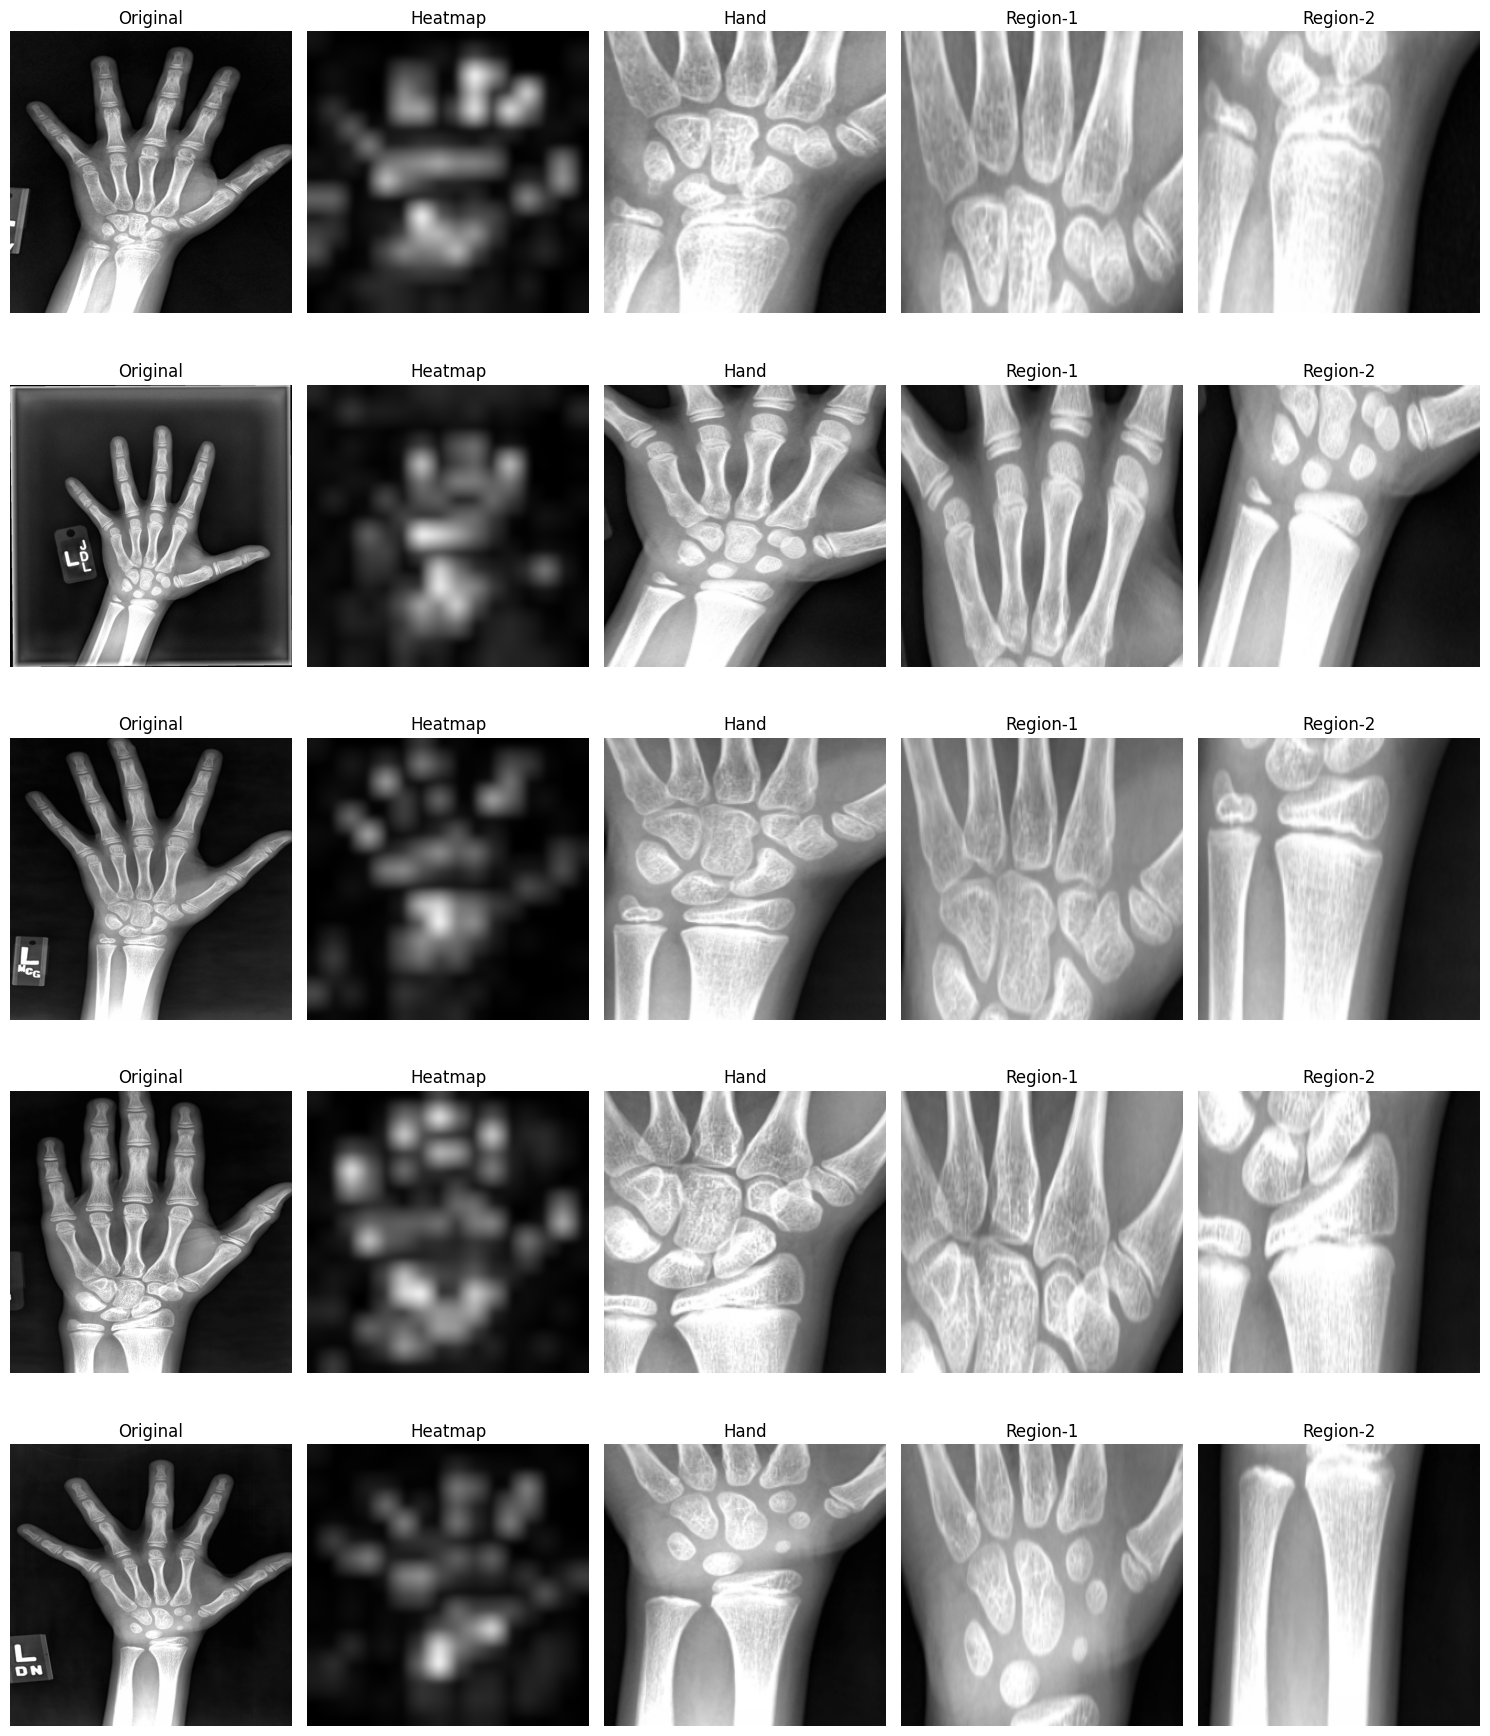

In [15]:
import os, random, cv2
import matplotlib.pyplot as plt

IMG_DIR = "/kaggle/input/notebookc31f18e9e3/basic_preprocessing"
HEATMAP_DIR = "/kaggle/working/heatmaps"
PATCH_DIR = "/kaggle/working/patches"

files = os.listdir(HEATMAP_DIR)
samples = random.sample(files, 5)

def read_rgb(path):
    img = cv2.imread(path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 18))

for i, f in enumerate(samples):
    img = read_rgb(f"{IMG_DIR}/{f}")
    heat = read_rgb(f"{HEATMAP_DIR}/{f}")
    hand = read_rgb(f"{PATCH_DIR}/hand/{f}")
    r1 = read_rgb(f"{PATCH_DIR}/region1/{f}")
    r2 = read_rgb(f"{PATCH_DIR}/region2/{f}")

    plt.subplot(5,5,i*5+1); plt.imshow(img); plt.title("Original"); plt.axis("off")
    plt.subplot(5,5,i*5+2); plt.imshow(heat); plt.title("Heatmap"); plt.axis("off")
    plt.subplot(5,5,i*5+3); plt.imshow(hand); plt.title("Hand"); plt.axis("off")
    plt.subplot(5,5,i*5+4); plt.imshow(r1); plt.title("Region-1"); plt.axis("off")
    plt.subplot(5,5,i*5+5); plt.imshow(r2); plt.title("Region-2"); plt.axis("off")

plt.tight_layout()
plt.show()


In [16]:
import shutil

shutil.make_archive(
    "/kaggle/working/heatmaps",
    "zip",
    HEATMAP_DIR
)

print("Saved heatmaps.zip")


Saved heatmaps.zip


In [17]:
import shutil

shutil.make_archive(
    "/kaggle/working/patches",
    "zip",
    PATCH_DIR
)

print("Saved patches.zip")


Saved patches.zip


In [24]:
# =========================
# RSNA Bone Age – Ordinal Patch Model (Final Optimized <4 MAE)
# =========================

import os, cv2, torch
import numpy as np
import pandas as pd
from tqdm import tqdm

import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torch.optim.lr_scheduler import CosineAnnealingLR

# -------------------------
# Config
# -------------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CSV_PATH = "/kaggle/input/rsna-bone-age/boneage-training-dataset.csv"
PATCH_DIR = "/kaggle/working/patches"

IMG_SIZE = 300
NUM_BINS = 240
SOFT_SIGMA = 1.5

BATCH_SIZE = 8          # try 16 if GPU allows
EPOCHS = 60
FREEZE_EPOCHS = 5

LR1 = 3e-4
NUM_WORKERS = 2

torch.backends.cudnn.benchmark = True

# -------------------------
# Soft labels
# -------------------------
def soft_label(age, sigma=SOFT_SIGMA):
    x = torch.arange(NUM_BINS, device=age.device).float()
    y = torch.exp(-(x - age.unsqueeze(1))**2 / (2*sigma**2))
    return y / y.sum(dim=1, keepdim=True)

# -------------------------
# Dataset
# -------------------------
class PatchDataset(Dataset):
    def __init__(self, df, train=True):
        self.df = df.reset_index(drop=True)
        self.train = train

        if train:
            self.tf = transforms.Compose([
                transforms.ToPILImage(),
                transforms.RandomRotation(15),
                transforms.RandomResizedCrop(IMG_SIZE, scale=(0.9,1.1)),
                transforms.ColorJitter(brightness=0.15, contrast=0.15),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.ToTensor(),
                transforms.Normalize([0.485,0.456,0.406],
                                     [0.229,0.224,0.225])
            ])
        else:
            self.tf = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize([0.485,0.456,0.406],
                                     [0.229,0.224,0.225])
            ])

    def load_img(self, folder, idx):
        path = os.path.join(PATCH_DIR, folder, f"{idx}.png")
        if not os.path.exists(path):
            raise FileNotFoundError(path)

        img = cv2.imread(path)
        if img is None:
            raise RuntimeError(path)

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        return self.tf(img)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        r = self.df.iloc[idx]

        hand = self.load_img("hand", r.id)
        r1   = self.load_img("region1", r.id)
        r2   = self.load_img("region2", r.id)

        gender = torch.tensor(float(r.male), dtype=torch.float32)

        age = torch.tensor(float(r.boneage), dtype=torch.float32)
        y_soft = soft_label(age.unsqueeze(0)).squeeze(0)

        return hand, r1, r2, gender, y_soft, age

# -------------------------
# Spatial Attention
# -------------------------
class SpatialAttention(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.conv = nn.Conv2d(c,1,1)
    def forward(self,x):
        return x * torch.sigmoid(self.conv(x))

# -------------------------
# Ordinal Patch Regressor
# -------------------------
class OrdinalPatchRegressor(nn.Module):
    def __init__(self):
        super().__init__()

        base = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
        base.aux_logits = False
        base.AuxLogits = None

        self.features = nn.Sequential(*list(base.children())[:-2])
        self.attn = SpatialAttention(2048)
        self.pool = nn.AdaptiveAvgPool2d((2,2))

        self.gender_fc = nn.Linear(1,16)

        self.fc = nn.Linear(2048*2*2 + 16, NUM_BINS)
        self.fc_sigma = nn.Linear(2048*2*2 + 16, 1)

    def forward(self, x, gender):
        f = self.features(x)
        f = self.attn(f)
        f = self.pool(f)
        f = torch.flatten(f,1)

        g = self.gender_fc(gender.unsqueeze(1))
        f = torch.cat([f,g],dim=1)

        logits = self.fc(f)
        sigma = F.softplus(self.fc_sigma(f)) + 1e-3

        return logits, sigma.squeeze(1)

# -------------------------
# Attention Aggregator
# -------------------------
class OrdinalAttentionAggregator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(NUM_BINS*3,256),
            nn.ReLU(),
            nn.Linear(256,3)
        )
    def forward(self, logits):
        B = logits.shape[0]
        flat = logits.view(B,-1)
        w = torch.softmax(self.net(flat),dim=1).unsqueeze(2)
        return torch.sum(w*logits,dim=1)

# -------------------------
# Full Model
# -------------------------
class Phase3OrdinalModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.hand_net = OrdinalPatchRegressor()
        self.r1_net   = OrdinalPatchRegressor()
        self.r2_net   = OrdinalPatchRegressor()
        self.agg = OrdinalAttentionAggregator()

    def forward(self,h,r1,r2,gender):
        l1,s1 = self.hand_net(h,gender)
        l2,s2 = self.r1_net(r1,gender)
        l3,s3 = self.r2_net(r2,gender)

        logits = torch.stack([l1,l2,l3],dim=1)
        sigma  = torch.stack([s1,s2,s3],dim=1)

        fused = self.agg(logits)
        return fused, sigma

# -------------------------
# Loss + Prediction
# -------------------------
def loss_fn(pred_logits, y_soft, sigma):
    kl = F.kl_div(F.log_softmax(pred_logits,dim=1), y_soft, reduction="batchmean")
    return kl + 0.01*sigma.mean()

def logits_to_age(logits):
    probs = torch.softmax(logits,dim=1)
    bins = torch.arange(NUM_BINS,device=logits.device).float()
    return torch.sum(probs*bins,dim=1)

# -------------------------
# Training
# -------------------------
def train():

    df = pd.read_csv(CSV_PATH)
    train_df = df.sample(frac=0.9, random_state=42)
    val_df   = df.drop(train_df.index)

    train_dl = DataLoader(PatchDataset(train_df,True),BATCH_SIZE,True,
                          num_workers=NUM_WORKERS,pin_memory=True)
    val_dl   = DataLoader(PatchDataset(val_df,False),BATCH_SIZE,False,
                          num_workers=NUM_WORKERS,pin_memory=True)

    model = Phase3OrdinalModel().to(DEVICE)

    # freeze backbone
    for net in [model.hand_net,model.r1_net,model.r2_net]:
        for p in net.features.parameters():
            p.requires_grad=False

    opt = optim.AdamW(model.parameters(),lr=LR1)
    scheduler = CosineAnnealingLR(opt, T_max=EPOCHS-FREEZE_EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler()

    best = 1e9

    for ep in range(EPOCHS):

        if ep==FREEZE_EPOCHS:
            for net in [model.hand_net,model.r1_net,model.r2_net]:
                for p in net.features.parameters():
                    p.requires_grad=True

        model.train()
        tr_mae = 0

        for h,r1,r2,gender,y_soft,y_age in tqdm(train_dl,desc=f"Epoch {ep+1}/{EPOCHS}"):

            h,r1,r2,gender = h.to(DEVICE),r1.to(DEVICE),r2.to(DEVICE),gender.to(DEVICE)
            y_soft,y_age = y_soft.to(DEVICE),y_age.to(DEVICE)

            with torch.amp.autocast("cuda"):
                pred,sigma = model(h,r1,r2,gender)
                loss = loss_fn(pred,y_soft,sigma)

            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            tr_mae += torch.mean(torch.abs(logits_to_age(pred)-y_age)).item()

        if ep>=FREEZE_EPOCHS:
            scheduler.step()

        tr_mae/=len(train_dl)

        model.eval()
        va_mae=0
        with torch.no_grad():
            for h,r1,r2,gender,y_soft,y_age in val_dl:
                h,r1,r2,gender = h.to(DEVICE),r1.to(DEVICE),r2.to(DEVICE),gender.to(DEVICE)
                y_age=y_age.to(DEVICE)

                p,_=model(h,r1,r2,gender)
                va_mae+=torch.mean(torch.abs(logits_to_age(p)-y_age)).item()

        va_mae/=len(val_dl)

        print(f"Train MAE={tr_mae:.3f} | Val MAE={va_mae:.3f}")

        if va_mae<best:
            best=va_mae
            torch.save(model.state_dict(),"phase3_best.pt")
            print("✅ Saved best")

    print("Training complete")

if __name__=="__main__":
    train()


Epoch 1/60: 100%|██████████| 1419/1419 [02:53<00:00,  8.20it/s]


Train MAE=28.861 | Val MAE=23.873
✅ Saved best


Epoch 2/60: 100%|██████████| 1419/1419 [02:56<00:00,  8.06it/s]


Train MAE=22.568 | Val MAE=19.690
✅ Saved best


Epoch 3/60: 100%|██████████| 1419/1419 [02:55<00:00,  8.11it/s]


...

Train MAE=5.257 | Val MAE=8.562


Epoch 32/60: 100%|██████████| 1419/1419 [06:28<00:00,  3.65it/s]


Train MAE=5.039 | Val MAE=8.233


Epoch 33/60:   3%|▎         | 44/1419 [00:14<07:40,  2.99it/s]


KeyboardInterrupt: 

In [25]:
# Stage-2 Stacked CAM Patch Regression with Patch-only Feature Fusion (PyTorch)
# Competition-tuned version (balanced regularization) to achieve < 4 MAE
# Kaggle compatible

import os, cv2, torch
import numpy as np
import pandas as pd
from tqdm import tqdm

import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torch.optim.lr_scheduler import CosineAnnealingLR

# ======================
# Config (TUNED)
# ======================
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CSV_PATH = "/kaggle/input/rsna-bone-age/boneage-training-dataset.csv"
PATCH_DIR = "/kaggle/working/patches"  # contains hand/, region1/, region2/

IMG_SIZE = 224
NUM_PATCHES = 3
BATCH_SIZE = 16
EPOCHS = 50
LR = 3e-4                 # tuned
WEIGHT_DECAY = 1e-4       # tuned
FREEZE_EPOCHS = 3
DROPOUT_RATE = 0.1        # tuned
EARLY_STOP_PATIENCE = 20

# ======================
# Dataset (moderate augmentation)
# ======================
class StackedPatchDataset(Dataset):
    def __init__(self, df, train=True):
        self.df = df.reset_index(drop=True)
        self.train = train

        if train:
            self.tf = transforms.Compose([
                transforms.ToPILImage(),
                transforms.RandomRotation(10),
                transforms.RandomResizedCrop(IMG_SIZE, scale=(0.9, 1.05)),
                transforms.ColorJitter(brightness=0.1, contrast=0.1),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor(),
                transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
            ])
        else:
            self.tf = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
            ])

    def load_patch(self, folder, idx):
        path = os.path.join(PATCH_DIR, folder, f"{idx}.png")
        assert os.path.exists(path), f"Missing patch {path}"
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        return self.tf(img)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        r = self.df.iloc[idx]

        p1 = self.load_patch("hand", r.id)
        p2 = self.load_patch("region1", r.id)
        p3 = self.load_patch("region2", r.id)

        stacked = torch.cat([p1, p2, p3], dim=0)  # (9,H,W)

        gender = torch.tensor(float(r.male), dtype=torch.float32)
        age = torch.tensor(float(r.boneage), dtype=torch.float32)

        return stacked, p1, gender, age

# ======================
# Patch-only feature extractor (frozen)
# ======================
class PatchOnlyFeatureNet(nn.Module):
    def __init__(self, backbone_path=None):
        super().__init__()
        base = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.features = nn.Sequential(*list(base.children())[:-2])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.embed_dim = 512
        self.embed_fc = nn.Linear(512, self.embed_dim)

        if backbone_path:
            sd = torch.load(backbone_path, map_location="cpu")
            self.load_state_dict(sd, strict=False)

        for p in self.parameters():
            p.requires_grad = False

    def forward(self, x):
        f = self.features(x)
        f = self.pool(f).flatten(1)
        f = self.embed_fc(f)
        return f

# ======================
# Stage-2 Regression Model
# ======================
class StackedPatchRegressionNet(nn.Module):
    def __init__(self, patch_feature_net=None, dropout=0.1):
        super().__init__()

        self.patch_feature_net = patch_feature_net
        self.use_patch_feat = patch_feature_net is not None

        base = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        base.conv1 = nn.Conv2d(9, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.backbone = nn.Sequential(*list(base.children())[:-2])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout_backbone = nn.Dropout(dropout)

        self.gender_fc = nn.Linear(1, 16)

        if self.use_patch_feat:
            self.patch_proj = nn.Linear(patch_feature_net.embed_dim, 64)

        fused_dim = 2048 + 16 + (64 if self.use_patch_feat else 0)

        self.regressor = nn.Sequential(
            nn.Linear(fused_dim, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 1)
        )

        if self.use_patch_feat:
            nn.init.normal_(self.patch_proj.weight, std=0.01)
            nn.init.zeros_(self.patch_proj.bias)

    def forward(self, stacked, gender, single_patch=None):
        f = self.backbone(stacked)
        f = self.pool(f).flatten(1)
        f = self.dropout_backbone(f)

        g = self.gender_fc(gender.unsqueeze(1))
        feats = [f, g]

        if self.use_patch_feat:
            with torch.no_grad():
                pf = self.patch_feature_net(single_patch)
            pf = self.patch_proj(pf)
            feats.append(pf)

        fused = torch.cat(feats, dim=1)
        age = self.regressor(fused).squeeze(1)
        return age

# ======================
# Training
# ======================

def train():
    df = pd.read_csv(CSV_PATH)
    train_df = df.sample(frac=0.9, random_state=42)
    val_df = df.drop(train_df.index)

    train_ds = StackedPatchDataset(train_df, True)
    val_ds = StackedPatchDataset(val_df, False)

    train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
    val_dl = DataLoader(val_ds, BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

    patch_feat_net = PatchOnlyFeatureNet(backbone_path=None)
    model = StackedPatchRegressionNet(patch_feat_net, dropout=DROPOUT_RATE).to(DEVICE)

    # Freeze backbone initially
    for p in model.backbone.parameters():
        p.requires_grad = False

    opt = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = CosineAnnealingLR(opt, T_max=EPOCHS-FREEZE_EPOCHS, eta_min=1e-6)

    scaler = torch.cuda.amp.GradScaler()

    best = 1e9
    patience_counter = 0

    for ep in range(EPOCHS):

        if ep == FREEZE_EPOCHS:
            for p in model.backbone.parameters():
                p.requires_grad = True

        model.train()
        tr = 0

        for stacked, p1, gender, age in tqdm(train_dl, desc=f"Epoch {ep+1}"):
            stacked = stacked.to(DEVICE)
            p1 = p1.to(DEVICE)
            gender = gender.to(DEVICE)
            age = age.to(DEVICE)

            with torch.cuda.amp.autocast():
                pred = model(stacked, gender, p1)
                loss = torch.mean(torch.abs(pred - age))

            opt.zero_grad()
            scaler.scale(loss).backward()

            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

            scaler.step(opt)
            scaler.update()

            tr += loss.item()

        tr /= len(train_dl)

        model.eval()
        va = 0
        with torch.no_grad():
            for stacked, p1, gender, age in val_dl:
                stacked = stacked.to(DEVICE)
                p1 = p1.to(DEVICE)
                gender = gender.to(DEVICE)
                age = age.to(DEVICE)

                pred = model(stacked, gender, p1)
                va += torch.mean(torch.abs(pred - age)).item()

        va /= len(val_dl)

        if ep >= FREEZE_EPOCHS:
            scheduler.step()

        print(f"Epoch {ep+1}: Train MAE {tr:.3f} | Val MAE {va:.3f}")

        if va < best:
            best = va
            patience_counter = 0
            torch.save(model.state_dict(), "stage2_best.pt")
            print("Saved best model")
        else:
            patience_counter += 1

        if patience_counter >= EARLY_STOP_PATIENCE:
            print(f"Early stopping at epoch {ep+1}")
            break

    print(f"Training complete. Best Val MAE: {best:.3f}")


if __name__ == "__main__":
    train()


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 169MB/s] 
/tmp/ipykernel_55/1068852415.py:186: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1:   0%|          | 0/710 [00:00<?, ?it/s]/tmp/ipykernel_55/1068852415.py:206: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1: 100%|██████████| 710/710 [02:00<00:00,  5.91it/s]


Epoch 1: Train MAE 30.461 | Val MAE 20.398
Saved best model


Epoch 2: 100%|██████████| 710/710 [01:56<00:00,  6.10it/s]


Epoch 2: Train MAE 20.049 | Val MAE 18.585
Saved best model


...

Epoch 6: Train MAE 19.277 | Val MAE 17.081
Saved best model


Epoch 7: 100%|██████████| 710/710 [02:06<00:00,  5.60it/s]


Epoch 7: Train MAE 18.920 | Val MAE 17.017
Saved best model


Epoch 8:   7%|▋         | 52/710 [00:10<02:13,  4.93it/s]


KeyboardInterrupt: 